# 06 - Đánh giá & Giải thích mô hình

**Mục tiêu:**
1. Đánh giá model XGBoost đã lưu (`models/model.pkl`) trên tập Test
2. Xem model dự đoán đúng/sai ở đâu (Confusion Matrix, ROC)
3. Biết model dùng đặc trưng nào để quyết định (Feature Importance, SHAP)

In [9]:
import sys
sys.path.append('../src')  # để load được class TelcoPreprocessor trong src/

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load model + preprocessor đã lưu ở bước trước
artifact = joblib.load('../models/model.pkl')
model = artifact['model']
threshold = artifact['threshold']
preprocessor = joblib.load('../models/preprocessor.pkl')

print('Threshold:', threshold)
print('ROC-AUC khi train:', round(artifact['roc_auc'], 4))
print('Số đặc trưng:', len(artifact['features']))

Threshold: 0.4
ROC-AUC khi train: 0.844
Số đặc trưng: 62


## 1. Dự đoán trên tập Test

Chia dữ liệu **giống hệt** `pipeline.py` (random_state=42) để có đúng tập Test mà model chưa từng thấy.

In [10]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

from sklearn.model_selection import train_test_split
_, X_test, _, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_test_processed = preprocessor.transform(X_test)

# Xác suất rời đi, rồi so với threshold để ra dự đoán
y_proba = model.predict_proba(X_test_processed)[:, 1]
y_pred = (y_proba >= threshold).astype(int)

print('Số khách trong tập Test:', len(y_test))

Số khách trong tập Test: 1409


## 2. Classification Report

- **Precision** (khi dự đoán "Rời đi"): dự đoán rời → bao nhiêu % thực sự rời. Sai ở đây = tốn tiền chăm sóc khách không cần.
- **Recall** (khách "Rời đi"): khách thực sự rời → model bắt được bao nhiêu %. **Sai ở đây = bỏ lỡ khách, họ rời mà mình không biết** → quan trọng nhất.

In [17]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 4))

              precision    recall  f1-score   support

           0       0.92      0.69      0.79      1035
           1       0.49      0.83      0.62       374

    accuracy                           0.73      1409
   macro avg       0.70      0.76      0.70      1409
weighted avg       0.80      0.73      0.74      1409

ROC-AUC: 0.8391


## 3. Confusion Matrix

4 ô:
- **Ô xanh đậm (TN):** khách ở lại → dự đoán ở lại 
- **Ô xanh nhạt (FN):** khách rời → dự đoán ở lại **(tệ nhất - bỏ lỡ khách)**
- **Ô xanh nhạt (FP):** khách ở lại → dự đoán rời (chăm sóc thừa, ít hại)
- **Ô xanh đậm (TP):** khách rời → dự đoán rời 

[[714 321]
 [ 65 309]]


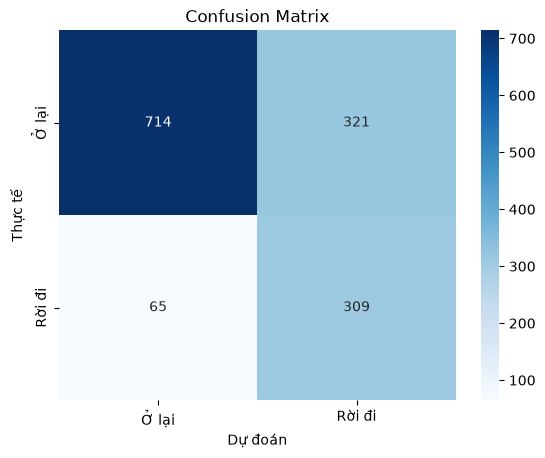

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ở lại', 'Rời đi'],
            yticklabels=['Ở lại', 'Rời đi'])
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title('Confusion Matrix')
plt.show()

## 4. ROC Curve

Đường càng cong lên góc trên bên trái càng tốt. **AUC = 0.5 là đoán bừa, 1.0 là hoàn hảo.**

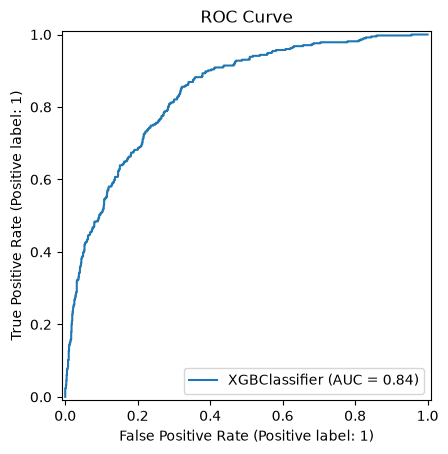

In [13]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(model, X_test_processed, y_test)
plt.title('ROC Curve')
plt.show()

## 5. Chọn Threshold

Threshold thấp → bắt được nhiều khách rời hơn (recall cao) nhưng dự đoán "rời" nhiều hơn (precision thấp).

**Mục tiêu giữ khách: ưu tiên Recall cao.**

In [14]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.6]:
    pred = (y_proba >= t).astype(int)
    p, r, _, _ = precision_recall_fscore_support(
        y_test, pred, average='binary', zero_division=0
    )
    rows.append({'threshold': t, 'precision': round(p, 3), 'recall': round(r, 3)})

pd.DataFrame(rows)

,threshold,precision,recall
0,0.30,0.458,0.885
1,0.35,0.479,0.869
2,0.40,0.490,0.826
3,0.45,0.504,0.791
4,0.50,0.517,0.759
5,0.60,0.572,0.671


## 6. Đặc trưng quan trọng nhất

XGBoost tự chấm điểm cột nào model dùng nhiều nhất để quyết định.

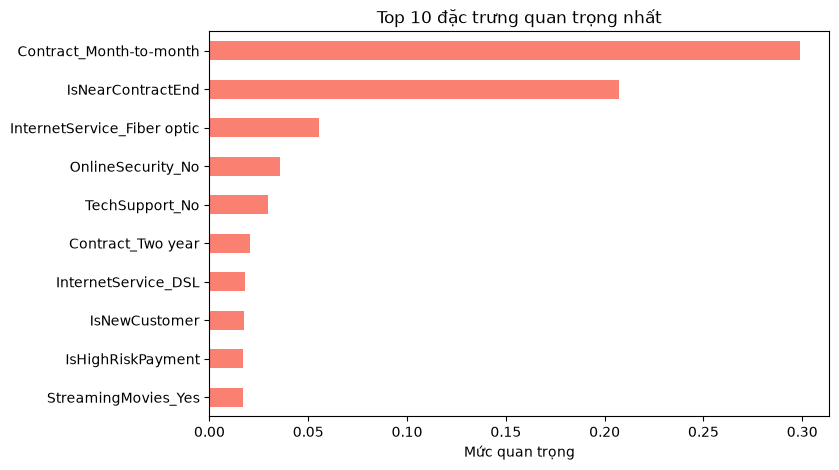

In [15]:
imp = pd.Series(model.feature_importances_, index=artifact['features'])

imp.sort_values().tail(10).plot(kind='barh', figsize=(8, 5), color='salmon')
plt.title('Top 10 đặc trưng quan trọng nhất')
plt.xlabel('Mức quan trọng')
plt.show()

## 7. SHAP - giải thích chi tiết từng dự đoán

SHAP cho biết mỗi đặc trưng **đẩy dự đoán đi hướng nào** (thuận = dễ rời, ngược = dễ ở lại).

> Chưa cài shap? Chạy `pip install shap` — hoặc bỏ qua bước này, phần trên đã đủ để báo cáo.

/home/loc-nguyen/PROJECT/AI/OCR/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


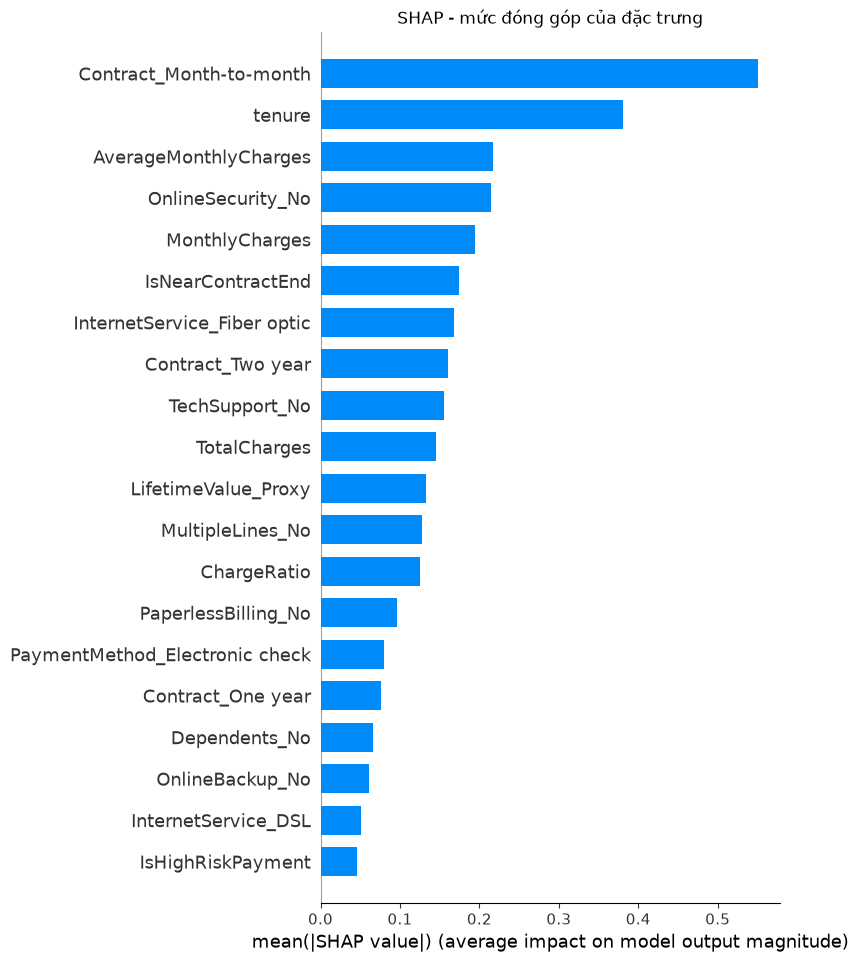

In [16]:
try:
    import shap

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test_processed)

    shap.summary_plot(shap_values, X_test_processed,
                      plot_type='bar', show=False)
    plt.title('SHAP - mức đóng góp của đặc trưng')
    plt.show()
except ImportError:
    print('Chưa cài shap -> chạy: pip install shap (bỏ qua cũng được)')

## Kết luận

- Sẽ cập nhật sau khi chạy (ROC-AUC, Recall, FP/FN, đặc trưng quan trọng nhất).